# Retail Promotion Effectiveness & Discount Sensitivity Analysis
## 04 — Coupon and Campaign Analysis

Validates campaign assignment and coupon relationships, reports redemption rates, and describes post-redemption eligible-product purchasing.

## Imports

In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 50)

## Config (file paths, plotting style, and reproducibility)

In [2]:
def find_project_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'README.md').exists():
            return candidate
    raise FileNotFoundError('Run from the repository or notebooks directory.')
PROJECT_ROOT = find_project_root()
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_utils import add_bar_labels, add_promotion_fields, bootstrap_ci, summarize_frame
RANDOM_STATE = 42
ALPHA = 0.05
POWER = 0.80
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

## Data Cleaning and Preprocessing

Campaign assignment is the redemption denominator. Coupon eligibility uses the observed coupon/campaign mapping; a redemption does not identify a single purchased product.

In [3]:
campaigns=pd.read_csv(RAW_DIR/'campaign_table.csv'); campaign_desc=pd.read_csv(RAW_DIR/'campaign_desc.csv'); coupons=pd.read_csv(RAW_DIR/'coupon.csv'); redemptions=pd.read_csv(RAW_DIR/'coupon_redempt.csv')
transactions=pd.read_csv(PROCESSED_DIR/'transaction_product_analysis.csv.gz',usecols=['household_key','DAY','PRODUCT_ID','SALES_VALUE'])

In [4]:
summarize_frame('coupon redemptions',redemptions,'DAY')

coupon redemptions row count: 2,318
coupon redemptions column count: 4
coupon redemptions null counts:
household_key    0
DAY              0
COUPON_UPC       0
CAMPAIGN         0
coupon redemptions exact duplicate count: 0
coupon redemptions DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 2318 entries, 0 to 2317
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   household_key  2318 non-null   int64
 1   DAY            2318 non-null   int64
 2   COUPON_UPC     2318 non-null   int64
 3   CAMPAIGN       2318 non-null   int64
dtypes: int64(4)
memory usage: 72.6 KB
coupon redemptions descriptive statistics for DAY:
count    2318.000000
mean      528.217429
std       100.360985
min       225.000000
25%       458.250000
50%       532.000000
75%       605.000000
max       704.000000


In [5]:
print('Rows with missing redemption fields:',int(redemptions.isna().any(axis=1).sum()))
redemptions_clean=redemptions.dropna().drop_duplicates().copy()
print('Rows after dropna and exact deduplication:',f'{len(redemptions_clean):,}')
print('No guessed event ID: multiple coupons can be redeemed by one household/day.')
print('Exact duplicate coupon-product-campaign mappings:',int(coupons.duplicated(['COUPON_UPC','PRODUCT_ID','CAMPAIGN']).sum()))
coupons_clean=coupons.drop_duplicates(['COUPON_UPC','PRODUCT_ID','CAMPAIGN']).copy()
print('Coupon mappings after verified-key deduplication:',f'{len(coupons_clean):,}')
timed=redemptions_clean.merge(campaign_desc,on='CAMPAIGN',how='left',validate='many_to_one')
timed['inside_campaign_window']=timed.DAY.between(timed.START_DAY,timed.END_DAY,inclusive='both')
print('Redemptions outside described campaign window:',int((~timed.inside_campaign_window).sum()))
print('Redemption DAY range:',redemptions_clean.DAY.min(),'to',redemptions_clean.DAY.max())

Rows with missing redemption fields: 0
Rows after dropna and exact deduplication: 2,318
No guessed event ID: multiple coupons can be redeemed by one household/day.
Exact duplicate coupon-product-campaign mappings: 5164
Coupon mappings after verified-key deduplication: 119,384
Redemptions outside described campaign window: 0
Redemption DAY range: 225 to 704


In [6]:
assert campaign_desc.CAMPAIGN.is_unique
assignments=campaigns.merge(campaign_desc,on=['CAMPAIGN','DESCRIPTION'],how='left',validate='many_to_one',indicator=True)
print('Description join:\n'+assignments._merge.value_counts().to_string()); assert (assignments._merge=='both').all(); assignments=assignments.drop(columns='_merge')
redemption_keys=redemptions_clean.groupby(['household_key','CAMPAIGN']).size().rename('redemption_events').reset_index()
outcomes=assignments.merge(redemption_keys,on=['household_key','CAMPAIGN'],how='left',validate='one_to_one'); outcomes.redemption_events=outcomes.redemption_events.fillna(0).astype(int); outcomes['redeemed']=outcomes.redemption_events>0
unmatched=redemption_keys.merge(campaigns[['household_key','CAMPAIGN']],how='left',indicator=True).query("_merge!='both'")
print('Redemption keys without assignment:',len(unmatched))

Description join:
_merge
both          7208
left_only        0
right_only       0
Redemption keys without assignment: 0


## Column Description

One line per assignment-outcome column with observed type.

In [7]:
display(pd.DataFrame({'column':outcomes.columns,'type':outcomes.dtypes.astype(str).values}))

,column,type
0,DESCRIPTION,str
1,household_key,int64
2,CAMPAIGN,int64
3,START_DAY,int64
4,END_DAY,int64
5,redemption_events,int64
6,redeemed,bool


## EDA

Rates use assigned household-campaign rows. Households can enter multiple campaigns, so row-level comparisons are descriptive.

In [8]:
campaign_summary=outcomes.groupby('DESCRIPTION').agg(assigned_household_campaigns=('household_key','size'),unique_households=('household_key','nunique'),redeemed_household_campaigns=('redeemed','sum'),redemption_events=('redemption_events','sum')).reset_index(); campaign_summary['redemption_rate_pct']=100*campaign_summary.redeemed_household_campaigns/campaign_summary.assigned_household_campaigns
display(campaign_summary); campaign_summary.to_csv(PROCESSED_DIR/'coupon_campaign_summary.csv',index=False)

,DESCRIPTION,assigned_household_campaigns,unique_households,redeemed_household_campaigns,redemption_events,redemption_rate_pct
0,TypeA,3979,1513,635,1791,15.958784
1,TypeB,2655,1023,210,454,7.909605
2,TypeC,574,397,44,73,7.665505


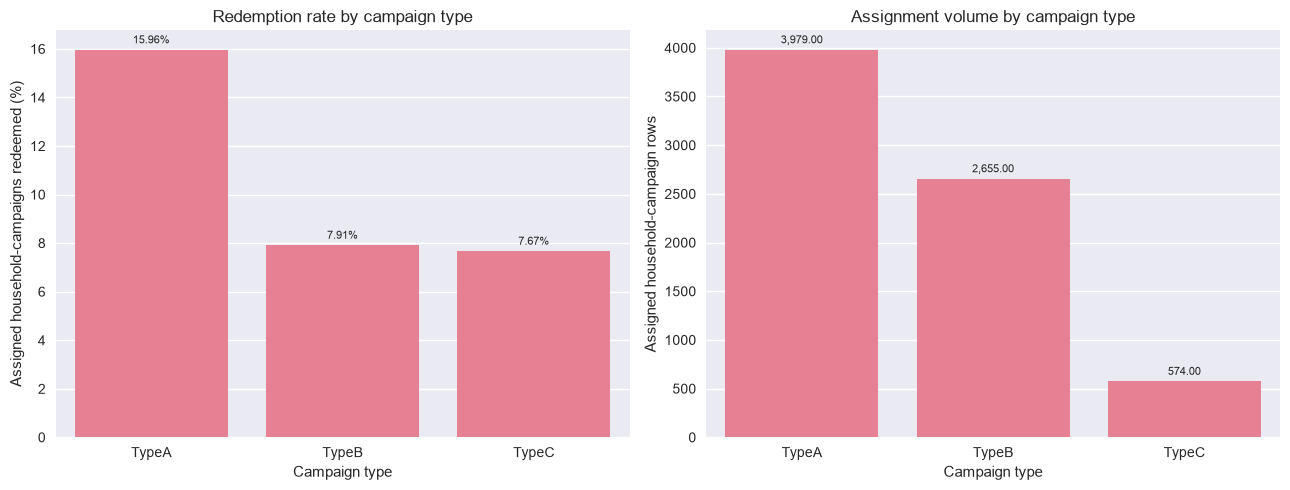

In [9]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
sns.barplot(data=campaign_summary,x='DESCRIPTION',y='redemption_rate_pct',ax=axes[0]); axes[0].set(title='Redemption rate by campaign type',xlabel='Campaign type',ylabel='Assigned household-campaigns redeemed (%)'); add_bar_labels(axes[0],True)
sns.barplot(data=campaign_summary,x='DESCRIPTION',y='assigned_household_campaigns',ax=axes[1]); axes[1].set(title='Assignment volume by campaign type',xlabel='Campaign type',ylabel='Assigned household-campaign rows'); add_bar_labels(axes[1])
plt.tight_layout(); plt.show()

## Problem Statement

Estimate coupon engagement with a valid assignment denominator, compare disjoint campaign-type cohorts, and describe later purchasing without claiming causality.

## Question 1 — Do exclusively Type A and Type B households have different any-redemption rates?

**Objective:** compare one binary outcome per household in non-overlapping cohorts. $H_0:p_A=p_B$. $H_1:p_A\ne p_B$. $\alpha=0.05$; power $=0.80$.

Planning uses $n=((z_{1-\alpha/2}\sqrt{2\bar p(1-\bar p)}+z_{1-\beta}\sqrt{p_1(1-p_1)+p_2(1-p_2)})/(p_2-p_1))^2$ per group. Planning rates 10% and 15% encode a five-point MDE, not findings. A proportions z-test is used only when expected cells are at least five; otherwise Fisher's exact test is selected.

In [10]:
def sample_size_two_proportions(p1,p2,alpha=.05,power=.80):
    pooled=(p1+p2)/2; num=stats.norm.ppf(1-alpha/2)*np.sqrt(2*pooled*(1-pooled))+stats.norm.ppf(power)*np.sqrt(p1*(1-p1)+p2*(1-p2)); return int(np.ceil((num/abs(p2-p1))**2))
types=campaigns.groupby('household_key').DESCRIPTION.agg(lambda x:frozenset(x)); exclusive=types[types.isin([frozenset(['TypeA']),frozenset(['TypeB'])])].to_frame('types'); exclusive['campaign_type']=exclusive.types.map(lambda x:next(iter(x))); exclusive['redeemed']=exclusive.index.isin(set(redemptions_clean.household_key)); counts=exclusive.groupby('campaign_type').redeemed.agg(['sum','count'])
required_n=sample_size_two_proportions(.10,.15,ALPHA,POWER); display(counts); print('Required per group:',required_n); print('Smaller cohort is underpowered.' if counts['count'].min()<required_n else 'Both cohorts meet target.')

,sum,count
campaign_type,,
TypeA,68,508
TypeB,6,60


Required per group: 686
Smaller cohort is underpowered.


In [11]:
success=counts.loc[['TypeA','TypeB'],'sum'].to_numpy(); totals=counts.loc[['TypeA','TypeB'],'count'].to_numpy(); pooled=success.sum()/totals.sum(); expected=np.r_[totals*pooled,totals*(1-pooled)]
print('Minimum expected cell:',expected.min()); print('Unique household units:',exclusive.index.is_unique); print('Campaign-type selection was not randomized.')

Minimum expected cell: 7.816901408450704
Unique household units: True
Campaign-type selection was not randomized.


In [12]:
if expected.min()>=5:
    statistic,p_value=proportions_ztest(success,totals); test_name='Two-proportion z-test'
else:
    statistic,p_value=stats.fisher_exact([[success[0],totals[0]-success[0]],[success[1],totals[1]-success[1]]]); test_name="Fisher's exact test"
rates=success/totals; difference=rates[0]-rates[1]; se=np.sqrt(rates[0]*(1-rates[0])/totals[0]+rates[1]*(1-rates[1])/totals[1]); ci_low,ci_high=difference+np.array([-1,1])*stats.norm.ppf(.975)*se; cohen_h=2*(np.arcsin(np.sqrt(rates[0]))-np.arcsin(np.sqrt(rates[1]))); decision='Reject H0' if p_value<ALPHA else 'Fail to reject H0'
print(f'{test_name}: statistic={statistic:.4f}, p-value={p_value:.6g}'); print(f'Rate difference: {difference:.4f}; 95% CI: [{ci_low:.4f}, {ci_high:.4f}]; Cohen h: {cohen_h:.4f}'); print(f'{decision}; this is an observational comparison.')

Two-proportion z-test: statistic=0.7368, p-value=0.461226
Rate difference: 0.0339; 95% CI: [-0.0476, 0.1153]; Cohen h: 0.1056
Fail to reject H0; this is an observational comparison.


## Question 2 — Is an eligible product purchased within 30 days after redemption?

This is descriptive. Coupons can map to multiple eligible products, and no randomized non-redeemer counterfactual exists; causal repeat-purchase inference is unavailable.

In [13]:
events=redemptions_clean.reset_index(names='redemption_event_id'); eligible=events.merge(coupons_clean,on=['COUPON_UPC','CAMPAIGN'],how='left',validate='many_to_many',indicator=True); print(eligible._merge.value_counts().to_string()); eligible=eligible.query("_merge=='both'").drop(columns='_merge')
candidates=eligible[['redemption_event_id','household_key','DAY','PRODUCT_ID']].merge(transactions,on=['household_key','PRODUCT_ID'],how='left',suffixes=('_redemption','_purchase'),validate='many_to_many'); candidates['within_30_days']=candidates.DAY_purchase.gt(candidates.DAY_redemption)&candidates.DAY_purchase.le(candidates.DAY_redemption+30)
repeat=candidates.groupby('redemption_event_id').within_30_days.any().reindex(events.redemption_event_id,fill_value=False); print(f'Events: {len(repeat):,}; with eligible-product purchase in 30 days: {repeat.sum():,}; rate: {100*repeat.mean():.2f}%')

_merge
both          2196662
left_only           0
right_only          0

Events: 2,318; with eligible-product purchase in 30 days: 835; rate: 36.02%


In [14]:
pd.DataFrame([{'exclusive_type_a_n':totals[0],'exclusive_type_b_n':totals[1],'type_a_rate':rates[0],'type_b_rate':rates[1],'rate_difference':difference,'ci_low':ci_low,'ci_high':ci_high,'p_value':p_value,'cohen_h':cohen_h,'redemption_events':len(repeat),'repeat_30d_rate':repeat.mean()}]).to_csv(PROCESSED_DIR/'coupon_inference_and_repeat.csv',index=False)

## Summary

- Joins and denominators were validated.
- Formal inference uses disjoint household cohorts with power, assumptions, effect size, CI, and decision.
- Thirty-day eligible-product purchasing is descriptive.

## Insights

- Overlapping campaigns invalidate naïve independent row tests.
- Redemption and later purchase can share propensity bias.
- Use randomized holdouts and verified delivery for causal measurement.